# Building a Perception

*The Mathematics of Machine Intelligence · Chapter 2*

Weigh two reports you cannot fully trust, and see when the weighing fails.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the readings, how steady each source has been over repeated attempts, and whether the sources could share an error or a steady offset. Then choose the matching card: precision weights for two unrelated unbiased reports, the Kalman gain when a running prediction meets a new reading, the variance formula when errors may move together, the causal-inference card when the reports may not describe one thing. Report the blend, its claimed and actual spread, and the assumption that would break it.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 2, Building a Perception: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'
SEEN, FELT = (58.0, 52.0)

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def gaussian(x, mean, sd):
    return np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * math.sqrt(2 * math.pi))

def blend(mu1, sd1, mu2, sd2):
    """Precision-weighted blend of two unbiased, unrelated readings of one quantity."""
    if not (sd1 > 0 and sd2 > 0):
        raise ValueError('Error standard deviations must be above zero.')
    tau1, tau2 = (1 / sd1 ** 2, 1 / sd2 ** 2)
    total = tau1 + tau2
    return {'tau1': tau1, 'tau2': tau2, 'w1': tau1 / total, 'w2': tau2 / total, 'estimate': (tau1 * mu1 + tau2 * mu2) / total, 'tau_post': total, 'sd_post': 1 / math.sqrt(total)}

def blend_picture(sight_sd=1.0, touch_sd=2.0):
    data = blend(SEEN, sight_sd, FELT, touch_sd)
    fig, ax = panels()
    x = np.linspace(40, 70, 600)
    ax[0].plot(x, gaussian(x, SEEN, sight_sd), color=TEAL, linewidth=2, label='sight alone')
    ax[0].plot(x, gaussian(x, FELT, touch_sd), color=TERRA, linewidth=2, linestyle='dashed', label='touch alone')
    ax[0].plot(x, gaussian(x, data['estimate'], data['sd_post']), color=NAVY, linewidth=3, label='blend')
    ax[0].axvline(data['estimate'], color=NAVY, linewidth=1, linestyle='dotted')
    top = ax[0].get_ylim()[1] * 1.15
    ax[0].set(xlabel='bar height (mm)', ylabel='relative likelihood', title='Each report and the blend', xlim=(46, 64), ylim=(0, top))
    tag(ax[0], data['estimate'], top * 0.985, f"{data['estimate']:.1f} mm", va='top', color=NAVY)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    grid = np.linspace(0.5, 8, 200)
    for other, style, colour in [(1.5, 'dotted', GREY), (2.0, 'solid', TEAL), (3.0, 'dashed', TERRA)]:
        curve = [blend(SEEN, s, FELT, other)['estimate'] for s in grid]
        chosen = other == touch_sd
        ax[1].plot(grid, curve, color=colour if not chosen else NAVY, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'touch sd {other:g}')
    ring(ax[1], sight_sd, data['estimate'])
    ax[1].axhline(SEEN, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].axhline(FELT, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].text(7.9, SEEN + 0.12, 'height shown to the eye', ha='right', va='bottom', fontsize=9, color=GREY)
    ax[1].text(7.9, FELT - 0.12, 'height felt by the fingers', ha='right', va='top', fontsize=9, color=GREY)
    ax[1].set(xlabel='sight error sd (mm), grainier to the right', ylabel='perceived height (mm)', title='The bar slides toward touch', ylim=(50.9, 59.1))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    across = 100 * (data['estimate'] - FELT) / (SEEN - FELT)
    metrics = {'Weight on sight': sig(data['w1']), 'Weight on touch': sig(data['w2']), 'Blended height (mm)': sig(data['estimate']), 'Blended error sd (mm)': sig(data['sd_post'])}
    summary = f"With sight error sd {sight_sd:g} mm and touch {touch_sd:g} mm, sight gets {sig(data['w1'])} of the say, so the bar seems {sig(data['estimate'])} mm tall, {across:.0f} percent of the way from the felt height to the seen one. The blend's error sd, {sig(data['sd_post'])} mm, is below both senses."
    calc = f"Precisions: sight {sig(data['tau1'])} = 1/{sight_sd:g}^2 and touch {sig(data['tau2'])} = 1/{touch_sd:g}^2. Height = ({sig(data['tau1'])} x {SEEN:g} + {sig(data['tau2'])} x {FELT:g}) / ({sig(data['tau1'])} + {sig(data['tau2'])}) = {sig(data['estimate'])} mm. Blended sd = 1/sqrt({sig(data['tau_post'])}) = {sig(data['sd_post'])} mm."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def precision_picture(touch_sd=2.0, sight_sd=1.0):
    data = blend(SEEN, sight_sd, FELT, touch_sd)
    best = min(sight_sd, touch_sd)
    fig, ax = panels()
    heights = [sight_sd, touch_sd, data['sd_post']]
    bars = ax[0].bar(['sight', 'touch', 'blend'], heights, color=[TEAL, TERRA, NAVY], width=0.6)
    ax[0].axhline(best, color=GREY, linestyle='dashed', linewidth=1.2, label='better single sense')
    for bar, h in zip(bars, heights):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + 0.06, sig(h), va='bottom')
    ax[0].set(ylabel='error sd (mm)', title='Blend versus each sense', ylim=(0, max(heights) * 1.3))
    ax[0].legend(fontsize=9, loc='upper right')
    ratio_grid = np.linspace(1, 8, 200)
    ax[1].plot(ratio_grid, 1 / np.sqrt(1 + 1 / ratio_grid ** 2), color=TEAL, linewidth=2.5, label='blend sd / better sd')
    ratio = max(sight_sd, touch_sd) / best
    value = data['sd_post'] / best
    ring(ax[1], ratio, value)
    ax[1].axhline(1, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].annotate('equal senses:\nbiggest gain', (1, 1 / math.sqrt(2)), textcoords='offset points', xytext=(18, -34), fontsize=9, color=DARK_GOLD, arrowprops={'arrowstyle': '->', 'color': DARK_GOLD})
    ax[1].set(xlabel='worse sd / better sd', ylabel='blend sd / better sd', title='The gain fades as one sense worsens', ylim=(0.6, 1.05))
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Blended error sd (mm)': sig(data['sd_post']), 'Better single sense (mm)': sig(best), 'Blend as a fraction of the better sense': sig(value), 'Share of the say held by touch': sig(data['w2'])}
    summary = f"Precisions add, so the blend's error sd, {sig(data['sd_post'])} mm, is below the better sense's {sig(best)} mm, at {sig(value)} of it. Touch keeps only {sig(data['w2'])} of the say, and the gain shrinks as the senses become unequal."
    calc = f"Precisions {sig(data['tau1'])} and {sig(data['tau2'])} add to {sig(data['tau_post'])}. Blended sd = 1/sqrt({sig(data['tau_post'])}) = {sig(data['sd_post'])} mm. Touch's share = {sig(data['tau2'])}/{sig(data['tau_post'])} = {sig(data['w2'])}. Ratio to the better sense = {sig(data['sd_post'])}/{sig(best)} = {sig(value)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def combined_variance(w1, sd1, sd2, rho):
    w2 = 1 - w1
    return w1 ** 2 * sd1 ** 2 + w2 ** 2 * sd2 ** 2 + 2 * w1 * w2 * rho * sd1 * sd2

def precision_weight_first(sd1, sd2):
    return 1 / sd1 ** 2 / (1 / sd1 ** 2 + 1 / sd2 ** 2)
SD1 = 2.0

def shared_error_picture(sd2=2.0, rho=0.0):
    w1 = precision_weight_first(SD1, sd2)
    actual = combined_variance(w1, SD1, sd2, rho)
    claimed = 1 / (1 / SD1 ** 2 + 1 / sd2 ** 2)
    better = min(SD1, sd2) ** 2
    fig, ax = panels()
    labels = ['better\nsense alone', 'claimed\n(unrelated)', 'actual']
    values = [better, claimed, actual]
    bars = ax[0].bar(labels, values, color=[GREY, TEAL, TERRA if actual > claimed + 1e-12 else NAVY], width=0.6)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.08, sig(v), va='bottom')
    ax[0].set(ylabel='error variance of the blend', title='What the blend claims and has', ylim=(0, max(max(values) * 1.2, 1)))
    grid = np.linspace(-0.5, 1, 151)
    for other, style, colour in [(2.0, 'solid', TEAL), (3.0, 'dashed', GOLD), (4.0, 'dotted', TERRA)]:
        w = precision_weight_first(SD1, other)
        curve = [combined_variance(w, SD1, other, r) for r in grid]
        chosen = other == sd2
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'second sd {other:g}')
    ax[1].axhline(SD1 ** 2, color=GREY, linewidth=1, linestyle='dotted')
    ring(ax[1], rho, actual)
    ax[1].text(-0.47, SD1 ** 2 + 0.12, 'first sense alone (variance 4)', ha='left', va='bottom', fontsize=9, color=GREY)
    ax[1].set(xlabel='error correlation (rho)', ylabel='error variance of the blend', title='Shared error erodes the gain', ylim=(0, 9.5))
    ax[1].legend(fontsize=9, loc='upper left')
    if actual < better - 1e-09:
        verdict = 'better than the better sense'
    elif abs(actual - better) <= 1e-09:
        verdict = 'same as the better sense'
    else:
        verdict = 'worse than the better sense'
    metrics = {'Actual error variance': sig(actual), 'Variance claimed if errors were unrelated': sig(claimed), 'Better sense alone': sig(better), 'Blend compared with the better sense': verdict}
    summary = f'The blend weights the first sense {sig(w1)} and the second {sig(1 - w1)} as if their errors were unrelated, claiming variance {sig(claimed)}. With correlation {sig(rho)} its actual variance is {sig(actual)}, which is {verdict}.'
    calc = f'w1 = (1/{SD1:g}^2) / (1/{SD1:g}^2 + 1/{sd2:g}^2) = {sig(w1)}, w2 = {sig(1 - w1)}. V = {sig(w1)}^2 x {SD1 ** 2:g} + {sig(1 - w1)}^2 x {sd2 ** 2:g} + 2 x {sig(w1)} x {sig(1 - w1)} x ({sig(rho)}) x {SD1:g} x {sd2:g} = {sig(actual)}. Claimed (rho = 0 and optimal weights): 1/(1/{SD1 ** 2:g} + 1/{sd2 ** 2:g}) = {sig(claimed)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def kalman_update(prediction, reading, prediction_variance, reading_variance):
    if prediction_variance < 0 or reading_variance < 0 or prediction_variance + reading_variance <= 0:
        raise ValueError('Variances must be nonnegative with a positive sum.')
    gain = prediction_variance / (prediction_variance + reading_variance)
    estimate = prediction + gain * (reading - prediction)
    variance = (1 - gain) * prediction_variance
    return {'gain': gain, 'estimate': estimate, 'variance': variance}
PREDICTION, READING = (10.0, 14.0)

def kalman_gain_picture(reading_variance=1.0, prediction_variance=4.0):
    data = kalman_update(PREDICTION, READING, prediction_variance, reading_variance)
    fig, ax = panels()
    x = np.linspace(4, 20, 600)
    ax[0].plot(x, gaussian(x, PREDICTION, math.sqrt(prediction_variance)), color=TERRA, linewidth=2, linestyle='dashed', label='prediction')
    ax[0].plot(x, gaussian(x, READING, math.sqrt(reading_variance)), color=TEAL, linewidth=2, label='reading')
    ax[0].plot(x, gaussian(x, data['estimate'], math.sqrt(data['variance'])), color=NAVY, linewidth=3, label='corrected')
    ax[0].axvline(data['estimate'], color=NAVY, linewidth=1, linestyle='dotted')
    top = ax[0].get_ylim()[1] * 1.15
    ax[0].set(xlabel='position (m)', ylabel='relative likelihood', title='Prediction, reading, correction', ylim=(0, top))
    tag(ax[0], data['estimate'], top * 0.985, f"{data['estimate']:.1f} m", va='top', color=NAVY)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    grid = np.geomspace(0.25, 32, 200)
    for p, style, colour in [(1.0, 'dotted', GREY), (4.0, 'solid', TEAL), (16.0, 'dashed', TERRA)]:
        chosen = p == prediction_variance
        ax[1].plot(grid, p / (p + grid), color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'prediction variance {p:g}')
    ring(ax[1], reading_variance, data['gain'])
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.25, 1, 4, 16])
    ax[1].set_xticklabels(['0.25', '1', '4', '16'])
    ax[1].set(xlabel='reading variance (R)', ylabel='gain (K)', title='A doubtful reading barely moves it', ylim=(0, 1.05))
    ax[1].legend(fontsize=9, loc='upper right')
    gap = READING - PREDICTION
    metrics = {'Gain (K)': sig(data['gain']), 'Corrected position (m)': sig(data['estimate']), 'Move from the prediction (m)': sig(data['gain'] * gap), 'Corrected variance': sig(data['variance'])}
    summary = f"With prediction variance {prediction_variance:g} and reading variance {reading_variance:g}, the gain is {sig(data['gain'])}, so the corrected position is {sig(data['estimate'])} m. A larger reading variance means a smaller gain and a smaller correction."
    calc = f"K = P/(P + R) = {prediction_variance:g}/({prediction_variance:g} + {reading_variance:g}) = {sig(data['gain'])}. Corrected = {PREDICTION:g} + {sig(data['gain'])} x ({READING:g} - {PREDICTION:g}) = {PREDICTION:g} + {sig(data['gain'] * gap)} = {sig(data['estimate'])} m. New variance = (1 - K) x P = {sig(data['variance'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PROCESS_VARIANCE = 1.0

def steady_gain(process_variance, reading_variance):
    """Steady-state Kalman gain for a position that follows a random walk."""
    q, r = (process_variance, reading_variance)
    prior = (q + math.sqrt(q * q + 4 * q * r)) / 2
    return prior / (prior + r)

def steady_error_variance(gain, process_variance, reading_variance):
    """Long-run variance of the estimate error when a fixed gain is used."""
    k, q, r = (gain, process_variance, reading_variance)
    return ((1 - k) ** 2 * q + k ** 2 * r) / (1 - (1 - k) ** 2)

def run_filter(readings, gain_start, assumed_reading_variance, process_variance=PROCESS_VARIANCE):
    """Scalar filter with the assumed noise level; returns the estimate after each reading."""
    estimate, variance = (gain_start, 10.0)
    out = []
    for z in readings:
        variance_prior = variance + process_variance
        gain = variance_prior / (variance_prior + assumed_reading_variance)
        estimate = estimate + gain * (z - estimate)
        variance = (1 - gain) * variance_prior
        out.append(estimate)
    return np.array(out)

def filter_noise_picture(assumed_r=1.0, true_r=16.0):
    k_assumed = steady_gain(PROCESS_VARIANCE, assumed_r)
    k_best = steady_gain(PROCESS_VARIANCE, true_r)
    rms = math.sqrt(steady_error_variance(k_assumed, PROCESS_VARIANCE, true_r))
    rms_best = math.sqrt(steady_error_variance(k_best, PROCESS_VARIANCE, true_r))
    raw = math.sqrt(true_r)
    rng = np.random.default_rng(2026)
    steps = 60
    truth = np.cumsum(rng.normal(0, math.sqrt(PROCESS_VARIANCE), steps))
    readings = truth + rng.normal(0, math.sqrt(true_r), steps)
    estimates = run_filter(readings, readings[0], assumed_r)
    fig, ax = panels()
    t = np.arange(1, steps + 1)
    ax[0].plot(t, readings, linestyle='none', marker='o', markersize=3.5, color=GOLD, label='readings')
    ax[0].plot(t, truth, color=NAVY, linewidth=2, label='true position')
    ax[0].plot(t, estimates, color=TEAL, linewidth=2, linestyle='dashed', label='filter estimate')
    ax[0].set(xlabel='reading number', ylabel='position (m)', title='One simulated run (seed 2026)')
    ax[0].legend(fontsize=9, loc='best')
    grid = [0.25, 0.5, 1, 2, 4, 8, 16, 32]
    for other, style, colour in [(1.0, 'dotted', GREY), (4.0, 'solid', TEAL), (16.0, 'dashed', TERRA)]:
        curve = [math.sqrt(steady_error_variance(steady_gain(PROCESS_VARIANCE, a), PROCESS_VARIANCE, other)) for a in grid]
        chosen = other == true_r
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'true noise variance {other:g}')
        ax[1].plot([other], [math.sqrt(steady_error_variance(steady_gain(PROCESS_VARIANCE, other), PROCESS_VARIANCE, other))], marker='v', markersize=7, color=colour)
    ring(ax[1], assumed_r, rms)
    ax[1].set_xscale('log')
    ax[1].set_xticks(grid)
    ax[1].set_xticklabels(['0.25', '0.5', '1', '2', '4', '8', '16', '32'])
    ax[1].set(xlabel='noise variance the filter assumes', ylabel='long-run error (rms, m)', title='Best when the assumption is right')
    ax[1].legend(fontsize=9, loc='upper right')
    metrics = {'Filter error, long run (rms, m)': sig(rms), 'Best possible with correct noise (m)': sig(rms_best), 'Raw readings error (m)': sig(raw), 'Gain the filter settles on': sig(k_assumed)}
    summary = f'A filter assuming noise variance {assumed_r:g} when the true value is {true_r:g} has long-run error {sig(rms)} m, against {sig(rms_best)} m with the right assumption and {sig(raw)} m for the raw readings. The curve on the right is exact; the run on the left is one seeded simulation.'
    calc = f'Position wanders with variance Q = {PROCESS_VARIANCE:g} per step. Assumed R = {assumed_r:g} gives a steady gain K = {sig(k_assumed)}. With true R = {true_r:g}, error variance = ((1 - K)^2 Q + K^2 R)/(1 - (1 - K)^2) = {sig(rms ** 2)}, so rms = {sig(rms)} m. The best gain {sig(k_best)} gives {sig(rms_best)} m.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SD_SIGHT, SD_SOUND, SD_PRIOR = (2.0, 8.0, 15.0)

def causal_inference(x_vision, x_sound, prior_common, sd_v=SD_SIGHT, sd_a=SD_SOUND, sd_p=SD_PRIOR):
    """Gaussian causal-inference observer: chance of one cause and the judged sound position."""
    v, a, p = (sd_v ** 2, sd_a ** 2, sd_p ** 2)
    denom1 = v * a + v * p + a * p
    like1 = math.exp(-0.5 * ((x_vision - x_sound) ** 2 * p + x_vision ** 2 * a + x_sound ** 2 * v) / denom1) / (2 * math.pi * math.sqrt(denom1))
    like2 = math.exp(-0.5 * (x_vision ** 2 / (v + p) + x_sound ** 2 / (a + p))) / (2 * math.pi * math.sqrt((v + p) * (a + p)))
    post_common = like1 * prior_common / (like1 * prior_common + like2 * (1 - prior_common))
    blended = (x_vision / v + x_sound / a) / (1 / v + 1 / a + 1 / p)
    separate = x_sound / a / (1 / a + 1 / p)
    return {'p_common': post_common, 'blended': blended, 'separate': separate, 'judged': post_common * blended + (1 - post_common) * separate}

def causal_inference_picture(separation=4, prior_common=0.5):
    data = causal_inference(float(separation), 0.0, prior_common)
    fig, ax = panels()
    grid = np.linspace(0.25, 20, 80)
    always = [causal_inference(g, 0.0, prior_common)['blended'] / g for g in grid]
    never = [causal_inference(g, 0.0, prior_common)['separate'] / g for g in grid]
    mixed = [causal_inference(g, 0.0, prior_common)['judged'] / g for g in grid]
    ax[0].plot(grid, always, color=GOLD, linewidth=1.8, linestyle='dashed', label='always blend')
    ax[0].plot(grid, never, color=GREY, linewidth=1.8, linestyle='dotted', label='never blend')
    ax[0].plot(grid, mixed, color=NAVY, linewidth=3, label='one cause or two')
    if separation:
        ring(ax[0], separation, data['judged'] / separation)
    else:
        ax[0].text(0.5, 0.5, 'light at the sound:\npull undefined', transform=ax[0].transAxes, ha='center', fontsize=10, color=TERRA)
    ax[0].set(xlabel="light's distance from the sound (degrees)", ylabel='pull: fraction of the way to the light', title="The light's pull weakens with distance", ylim=(-0.03, 1.03))
    ax[0].legend(fontsize=9, loc='upper right')
    grid2 = np.linspace(0, 20, 81)
    for pc, style, colour in [(0.2, 'dotted', GREY), (0.5, 'solid', TEAL), (0.8, 'dashed', TERRA)]:
        chosen = pc == prior_common
        ax[1].plot(grid2, [causal_inference(g, 0.0, pc)['p_common'] for g in grid2], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'expected common cause {pc:g}')
    ring(ax[1], separation, data['p_common'])
    ax[1].set(xlabel="light's distance from the sound (degrees)", ylabel='chance of one cause', title='Far apart means probably two', ylim=(-0.02, 1.02))
    ax[1].legend(fontsize=9, loc='upper right')
    if separation:
        pull = sig(data['judged'] / separation)
    else:
        pull = 'undefined (the light is at the sound)'
    metrics = {'Chance the observer assigns to one cause': sig(data['p_common']), 'Pull of the light on the sound': pull, 'Judged sound position if blended (degrees)': sig(data['blended']), 'Judged sound position, one cause or two (degrees)': sig(data['judged'])}
    summary = f"At {separation:g} degrees apart, the observer gives one cause a chance of {sig(data['p_common'])}, so the judged sound position is {sig(data['judged'])} degrees, between the separate answer, {sig(data['separate'])}, and the blended answer, {sig(data['blended'])}. A higher expected chance of a common cause strengthens the pull."
    calc = f"Judged = P(one cause) x blended + (1 - P) x separate = {sig(data['p_common'])} x {sig(data['blended'])} + {sig(1 - data['p_common'])} x {sig(data['separate'])} = {sig(data['judged'])} degrees. The sound is at 0 and the light measured at {separation:g}; error sds are {SD_SIGHT:g} (sight), {SD_SOUND:g} (sound), prior {SD_PRIOR:g}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SD_BODY, SD_INSTRUMENT = (3.0, 1.0)

def bias_mse(weight_on_body, bias, sd_body=SD_BODY, sd_instrument=SD_INSTRUMENT):
    """Mean squared error of w x body + (1 - w) x instrument when only the body sense is biased."""
    w = weight_on_body
    return w ** 2 * (bias ** 2 + sd_body ** 2) + (1 - w) ** 2 * sd_instrument ** 2

def best_body_weight(bias, sd_body=SD_BODY, sd_instrument=SD_INSTRUMENT):
    return sd_instrument ** 2 / (sd_instrument ** 2 + sd_body ** 2 + bias ** 2)

def bias_picture(weight_on_body=0.1, body_bias=6):
    mse = bias_mse(weight_on_body, body_bias)
    precision_w = best_body_weight(0)
    best_w = best_body_weight(body_bias)
    bias_part = (weight_on_body * body_bias) ** 2
    spread_part = mse - bias_part
    fig, ax = panels()
    parts = [bias_part, spread_part]
    bars = ax[0].bar(['steady offset\n(bias squared)', 'scatter\n(variance)'], parts, color=[TERRA, TEAL], width=0.55)
    top = max(mse * 1.25, 1.2)
    for bar, v in zip(bars, parts):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + top * 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='squared error of the blend', title=f'Total squared error {sig(mse)}', ylim=(0, top))
    grid = np.linspace(0, 1, 201)
    for b, style, colour in [(0, 'solid', TEAL), (3, 'dashed', GOLD), (6, 'dotted', TERRA)]:
        chosen = b == body_bias
        ax[1].plot(grid, [bias_mse(w, b) for w in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'inner ear bias {b:g}')
        ax[1].plot([best_body_weight(b)], [bias_mse(best_body_weight(b), b)], marker='v', markersize=7, color=colour)
    ax[1].axvline(precision_w, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].text(precision_w + 0.015, 0.62, 'weight the rule gives\nwith no bias', fontsize=9, color=GREY, va='bottom')
    ring(ax[1], weight_on_body, mse)
    ax[1].set_yscale('log')
    ax[1].set_yticks([0.7, 1, 2, 5, 10, 20, 50])
    ax[1].set_yticklabels(['0.7', '1', '2', '5', '10', '20', '50'])
    ax[1].set(xlabel='weight on the inner ear', ylabel='squared error (log scale)', title='A biased sense deserves less', ylim=(0.6, 60), xlim=(-0.02, 1.02))
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Squared error of the blend': sig(mse), 'Part from steady offset': sig(bias_part), 'Best weight on the inner ear': sig(best_w), 'Weight the unbiased rule gives': sig(precision_w)}
    summary = f"With inner-ear bias {body_bias:g} and weight {weight_on_body:g} on it, the blend's squared error is {sig(mse)}: {sig(bias_part)} from the offset and {sig(spread_part)} from scatter. The best weight is {sig(best_w)}, against {sig(precision_w)} from the rule that assumes no bias."
    calc = f'MSE = w^2 (b^2 + sd_ear^2) + (1 - w)^2 sd_instrument^2 = {weight_on_body:g}^2 x ({body_bias:g}^2 + {SD_BODY:g}^2) + (1 - {weight_on_body:g})^2 x {SD_INSTRUMENT:g}^2 = {sig(mse)}. Best w = sd_instrument^2 / (sd_instrument^2 + sd_ear^2 + b^2) = {SD_INSTRUMENT ** 2:g}/({SD_INSTRUMENT ** 2:g} + {SD_BODY ** 2:g} + {body_bias ** 2:g}) = {sig(best_w)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C02-D01: Where does a bar seem to be when sight and touch disagree?

If the eye is shown 58 mm and the fingers feel 52 mm, how tall does the bar seem, and how does that change as the picture grows grainy?

Each sense gives a height and misses by some typical amount. Dividing one by the squared miss gives a precision, and the rule counts each report in proportion to its precision. A sense with half the error sd has four times the precision, so a sharp sense gets a large share and a fuzzy one a small share, never zero.

$$
\hat s=\frac{\tau_1\mu_1+\tau_2\mu_2}{\tau_1+\tau_2},\qquad \tau_i=\frac{1}{\sigma_i^{2}},\qquad \tau_{\text{post}}=\tau_1+\tau_2
$$

**Symbols:** mu_1, mu_2: the seen height (58 mm) and the felt height (52 mm); sigma_i: error standard deviation of sense i in mm; it must be above zero; tau_i: precision of sense i, one divided by its squared standard deviation; s-hat: the blended height; tau_post: precision of the blend: the two precisions added

**Predict before looking:** With touch at 2 mm, predict how large the sight error sd must be for the bar to seem exactly halfway, 55 mm, before moving the slider.

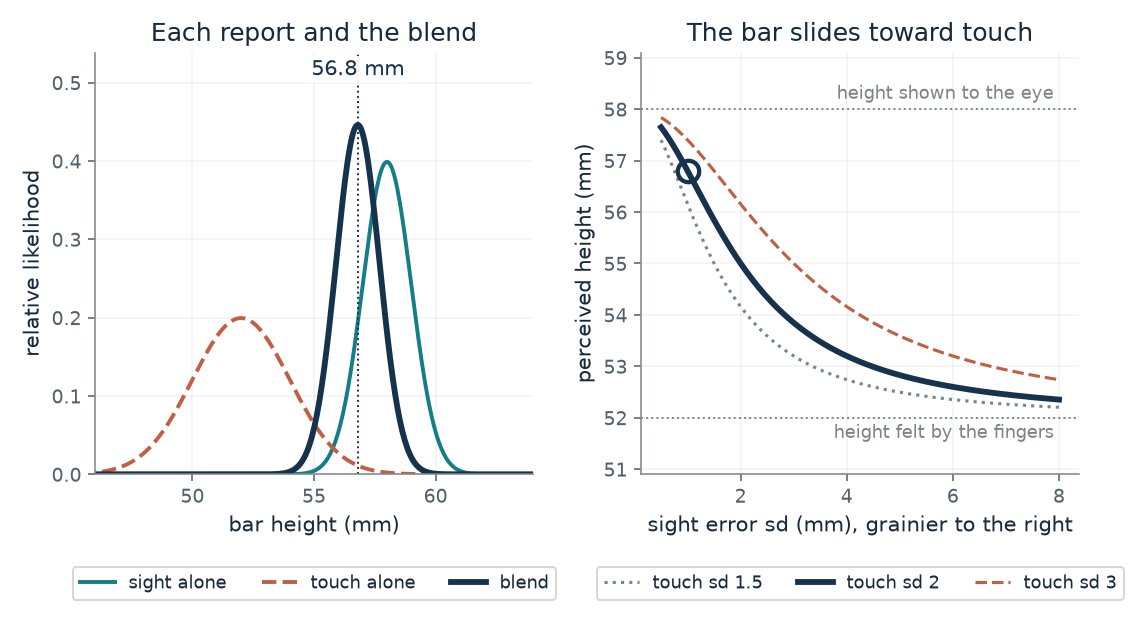

- **Weight on sight:** 0.8
- **Weight on touch:** 0.2
- **Blended height (mm):** 56.8
- **Blended error sd (mm):** 0.894

With sight error sd 1 mm and touch 2 mm, sight gets 0.8 of the say, so the bar seems 56.8 mm tall, 80 percent of the way from the felt height to the seen one. The blend's error sd, 0.894 mm, is below both senses.

Precisions: sight 1 = 1/1^2 and touch 0.25 = 1/2^2. Height = (1 x 58 + 0.25 x 52) / (1 + 0.25) = 56.8 mm. Blended sd = 1/sqrt(1.25) = 0.894 mm.

In [2]:
figure, values, explanation = blend_picture(**{'sight_sd': 1.0, 'touch_sd': 2.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Where does a bar seem to be when sight and touch disagree?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sight error sd (mm), grainier is larger = 2.0, Touch error sd (mm) = 2.0: At sight sd 2 mm, equal to touch's, the two precisions match, each sense gets half the say, and the bar seems 55 mm tall. Making the picture grainier than that hands the larger share to touch.

**Takeaway:** The blend leans toward the steadier sense, and each step in picture grain slides it further toward touch.

**Why it matters:** Any system that combines two noisy reports of one quantity has to decide how much each counts. This rule answers that when the error spreads are known and the errors are unrelated.

**In brains and behavior:** Four observers in the Ernst and Banks experiment judged as if each sense counted in proportion to its reliability. That is a fit to behavior, not a finding about neurons.

**In machines:** A sensor-fusion routine can compute the same weights from the stated error spreads of its sensors, if their errors are unbiased and unrelated.

**Where it applies:** Each sense is unbiased, the two errors are unrelated, and each error sd is known and above zero. The formula describes a blend of two reports; it does not show that the brain does this arithmetic.

**Check your understanding:** The picture is very grainy (sight sd 4 mm) and touch sd is 2 mm. Which sense gets more say, and what height does the bar seem?

<details><summary>Show the answer</summary>

Touch has four times the precision (0.25 against 0.0625), so it gets 0.8 of the say and sight 0.2. The bar seems 52 + 0.2 x 6 = 53.2 mm tall.

</details>

*Source: Chapter 2, The bar seemed to be where the clearer sense put it. Book formula (the Ernst and Banks rule). The 58 and 52 mm heights are the chapter's example; the error sds are made-up illustrations, not measurements from the study, whose points appear only on a graph.*

## C02-D02: Why can two senses beat the better one?

If touch is the weaker sense, does adding it help, and when does it help most?

Picking the better sense ignores what the other knows. Two reports whose errors are unrelated partly cancel each other's misses, so the blend scatters less than either. The gain is greatest when the senses are equally sharp and fades as one gets worse. Doubling a sense's error sd cuts its precision to a quarter, and its share follows, so a sense loses say faster than it loses accuracy.

$$
\tau_{\text{post}}=\tau_1+\tau_2,\qquad \sigma_{\text{post}}=\frac{1}{\sqrt{\tau_1+\tau_2}}
$$

**Symbols:** tau_1, tau_2: precisions of the two senses; tau_post: precision of the blend; sigma_post: error standard deviation of the blend, in mm

**Predict before looking:** With sight at 1 mm, predict which touch error sd gives the largest gain over the better sense, then check it.

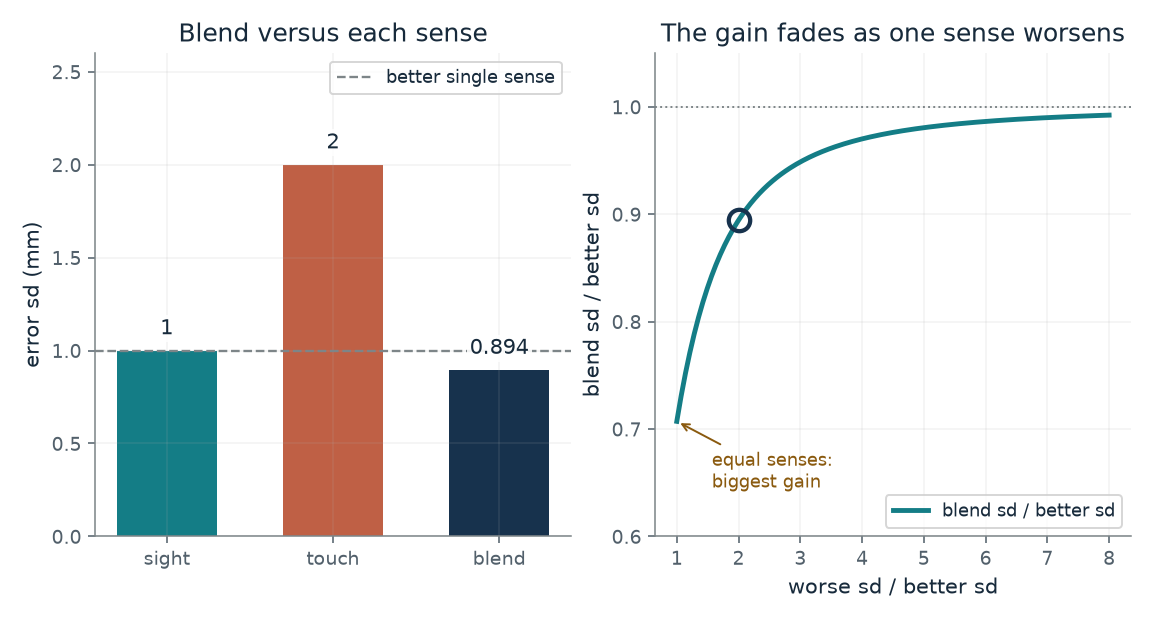

- **Blended error sd (mm):** 0.894
- **Better single sense (mm):** 1
- **Blend as a fraction of the better sense:** 0.894
- **Share of the say held by touch:** 0.2

Precisions add, so the blend's error sd, 0.894 mm, is below the better sense's 1 mm, at 0.894 of it. Touch keeps only 0.2 of the say, and the gain shrinks as the senses become unequal.

Precisions 1 and 0.25 add to 1.25. Blended sd = 1/sqrt(1.25) = 0.894 mm. Touch's share = 0.25/1.25 = 0.2. Ratio to the better sense = 0.894/1 = 0.894.

In [3]:
figure, values, explanation = precision_picture(**{'touch_sd': 2.0, 'sight_sd': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can two senses beat the better one?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Touch error sd (mm) = 1.0, Sight error sd (mm) = 1.0: With two equally sharp senses, the blend's sd is 1/sqrt(2), about 0.707 of either sense's. Every other setting here gains less.

**Takeaway:** Precisions add, so the blend is always sharper than the better sense, and most so when the senses are equally sharp.

**Why it matters:** Picking the better source throws away what the other one knows. Two unrelated reports partly cancel each other's misses, so a combiner that keeps both can do better than the best single source.

**In brains and behavior:** In the experiment the gain over the better sense was clearest when the picture was grainy, which is when the two senses were closer in sharpness.

**In machines:** A system that fuses two sensors gains most when they are about equally reliable, and little when one is far worse.

**Where it applies:** Unbiased, unrelated errors with positive finite sds. If the errors are related or biased, the blend can be worse than the better sense; the next illustrations show how.

**Check your understanding:** Two independent thermometers have error sds of 2 and 4 degrees. What is the blend's error sd, and how does that compare with the better thermometer?

<details><summary>Show the answer</summary>

Precisions are 0.25 and 0.0625, summing to 0.3125, so the blend's sd is 1/sqrt(0.3125) = 1.79 degrees, about 0.89 of the better thermometer's 2.

</details>

*Source: Chapter 2, Two senses judge more finely than either. Book formula with made-up error sds (sight 1 mm and touch 2 mm are the chapter's constructed numbers; the sight sd can also be 2 mm). The study's thresholds are proportional to, not equal to, standard deviations, so only ratios transfer.*

## C02-D03: When do two agreeing thermometers count as one witness?

If two sensors share some of their error, how much does their agreement really tell us?

The blend's variance has a cross term that depends on how far the two errors move together. Two thermometers in the same sunny window that both read two degrees high agree with each other and are both wrong, so they are closer to one witness repeated. The usual weights assume the cross term is zero; when it is not, the real variance exceeds the claimed one.

$$
V=w_1^2\sigma_1^2+w_2^2\sigma_2^2+2w_1w_2\rho\,\sigma_1\sigma_2
$$

**Symbols:** V: error variance of the weighted blend; w_1, w_2: weights, which add to one; sigma_1, sigma_2: error standard deviations of the two reports; rho: error correlation, from -1 to 1; 0 means no linear correlation

**Predict before looking:** Hold the second sensor's error sd at 3. Predict whether positively related errors can make the precision-weighted blend worse than the better sensor alone, and from about which correlation.

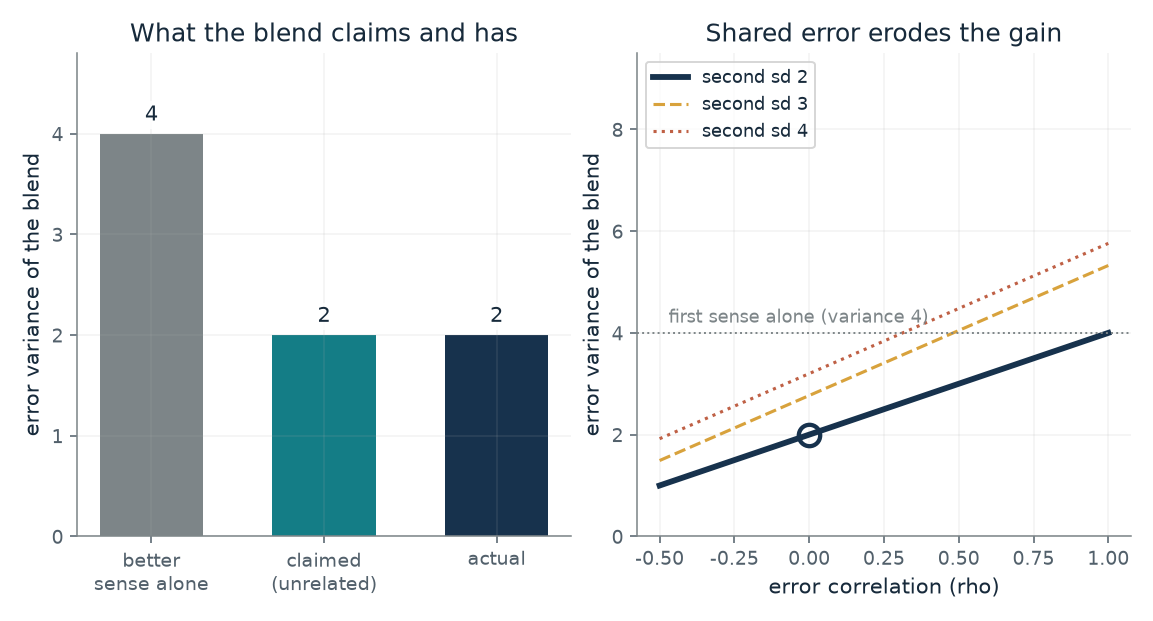

- **Actual error variance:** 2
- **Variance claimed if errors were unrelated:** 2
- **Better sense alone:** 4
- **Blend compared with the better sense:** better than the better sense

The blend weights the first sense 0.5 and the second 0.5 as if their errors were unrelated, claiming variance 2. With correlation 0 its actual variance is 2, which is better than the better sense.

w1 = (1/2^2) / (1/2^2 + 1/2^2) = 0.5, w2 = 0.5. V = 0.5^2 x 4 + 0.5^2 x 4 + 2 x 0.5 x 0.5 x (0) x 2 x 2 = 2. Claimed (rho = 0 and optimal weights): 1/(1/4 + 1/4) = 2.

In [4]:
figure, values, explanation = shared_error_picture(**{'rho': 0.0, 'sd2': 2.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When do two agreeing thermometers count as one witness?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Error correlation (rho) = 0.5, Second sensor error sd = 3.0: At sd 3 and correlation 0.5 the blend's variance is about 4.05, above the better sensor's 4. The weights were chosen as if errors were unrelated, and the blend has become worse than the better sensor alone. The tipping point is a correlation near 0.48.

**Takeaway:** Treating related errors as unrelated makes a blend claim more reliability than it has, and past some correlation it is worse than the better source alone.

**Why it matters:** A fusion rule that adds precisions without asking whether errors are shared can report confidence it has not earned. Asking whether sources err together comes before asking how to weight them.

**In brains and behavior:** In the slant study, six of eight observers did better with two visual cues than with either alone, and the fit held for three only when some shared error was allowed. Both cues reach the brain through one image.

**In machines:** A system built to assume unrelated errors adds the precisions anyway. With positively related errors it reports more reliability than it has.

**Where it applies:** Nonnegative weights that add to one and unbiased errors. A correlation of zero is no linear correlation, which does not by itself prove independence. Negative correlation can help errors cancel.

**Check your understanding:** Two equally weighted thermometers each have error sd 2. At what correlation does the blend have the same variance as one thermometer alone?

<details><summary>Show the answer</summary>

With equal sds and weights one half, V = 2 + 2 rho, which equals 4 only when rho = 1. When the errors move perfectly together, the second thermometer adds nothing.

</details>

*Source: Chapter 2, Two thermometers are one witness. Book formula (Oruc, Maloney and Landy as the chapter presents it). All numbers are constructed: the first sd is 2, the second is chosen, and the weights are the precision weights computed as if errors were unrelated.*

## C02-D04: How far should a new reading move a running prediction?

A navigation filter predicts 10 m and then reads 14 m. Where should its estimate land?

The prediction is one report and the new reading is the other. The gain K compares their uncertainties and says what fraction of the gap between them to cover. A trusted reading pulls the estimate a long way, and a doubtful reading barely moves it. This is the precision rule written as a prediction plus a correction.

$$
\hat{x}=\hat{x}^{-}+K(z-\hat{x}^{-}),\qquad K=\frac{P^{-}}{P^{-}+R}
$$

**Symbols:** x-hat^-: the prediction before the reading, 10 m; z: the reading, 14 m; P^-: error variance of the prediction (squared units); R: error variance of the reading (squared units); K: gain: the fraction of the gap used for the correction; x-hat: the corrected estimate

**Predict before looking:** With prediction variance 4, predict the reading variance at which the filter splits the difference and lands halfway at 12 m.

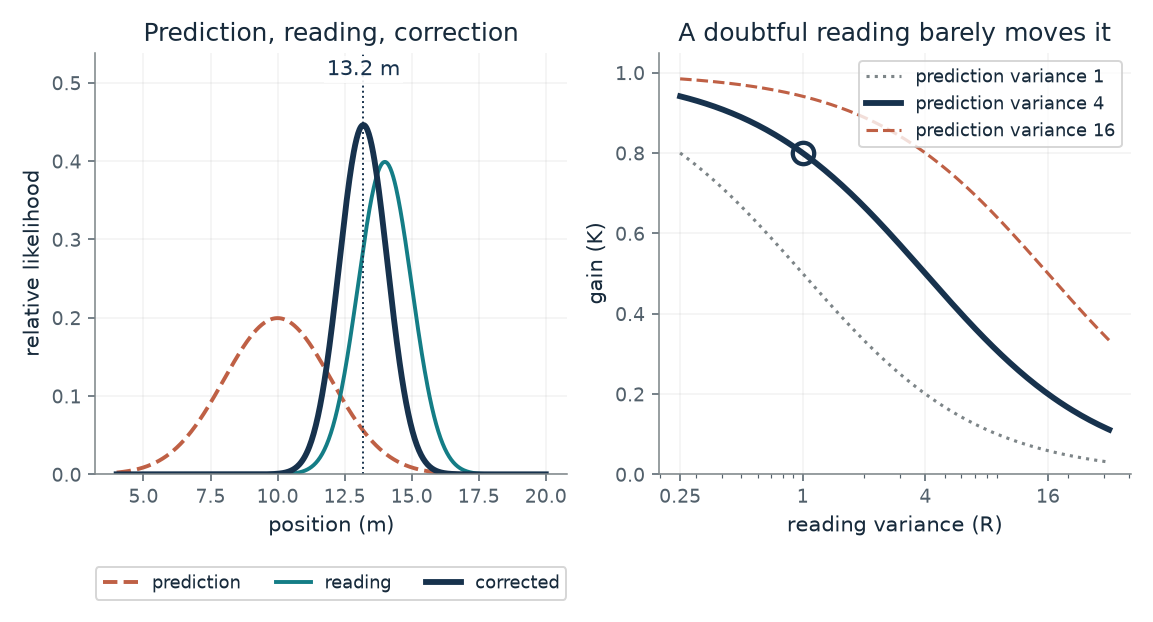

- **Gain (K):** 0.8
- **Corrected position (m):** 13.2
- **Move from the prediction (m):** 3.2
- **Corrected variance:** 0.8

With prediction variance 4 and reading variance 1, the gain is 0.8, so the corrected position is 13.2 m. A larger reading variance means a smaller gain and a smaller correction.

K = P/(P + R) = 4/(4 + 1) = 0.8. Corrected = 10 + 0.8 x (14 - 10) = 10 + 3.2 = 13.2 m. New variance = (1 - K) x P = 0.8.

In [5]:
figure, values, explanation = kalman_gain_picture(**{'reading_variance': 1.0, 'prediction_variance': 4.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far should a new reading move a running prediction?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Reading variance (R) = 4.0, Prediction variance (P) = 4.0: When the reading is exactly as uncertain as the prediction, the gain is 0.5 and the estimate lands halfway, at 12 m. A more doubtful reading moves it less; a more trusted one moves it more.

**Takeaway:** The gain is the reading's share of the weighing: the more uncertain the prediction is compared with the reading, the larger the correction.

**Why it matters:** A filter that corrects a running prediction with each new reading uses this one line every cycle; its quality depends on being told honest variances.

**In brains and behavior:** The chapter claims only that the filter's arithmetic matches the weighing. It does not show that the brain runs a filter.

**In machines:** Navigation systems repeat this predict-then-correct cycle with each measurement, with the noise levels measured or tuned beforehand.

**Where it applies:** Unbiased, unrelated errors and a nonnegative variance sum that is positive. This is one correction step, not the full filter with its model of how the state changes between readings.

**Check your understanding:** The prediction variance is 4 and the reading variance is 16. Find the gain and the corrected position.

<details><summary>Show the answer</summary>

K = 4/(4 + 16) = 0.2, so the corrected position is 10 + 0.2 x 4 = 10.8 m. The doubtful reading moves the estimate only a fifth of the way.

</details>

*Source: Chapter 2, A navigation computer does the same sum. Book formula (the scalar Kalman correction). The 10 m prediction, 14 m reading and variances 4 and 1 are the chapter's illustrative numbers.*

## C02-D05: What does a filter lose when it is told the wrong noise level?

If a filter believes its sensor is better or worse than it really is, how much worse does its estimate get?

A filter turns its assumed noise levels into a gain. If it assumes the sensor is better than it is, the gain is too large and the estimate chases the noise. If it assumes the sensor is worse, the gain is too small and the estimate lags the real motion. Only when the assumed level equals the true one is the gain the best available.

$$
S=\frac{(1-K)^2Q+K^2R}{1-(1-K)^2},\qquad K^{*}=\frac{P^{-}}{P^{-}+R},\quad P^{-}=\frac{Q+\sqrt{Q^2+4QR}}{2}
$$

**Symbols:** Q: variance of how far the true position wanders between readings (1 here); R: true variance of the sensor's reading error; K: the steady gain the filter settles on, from the noise level it assumes; S: long-run error variance of the filter's estimate; K*, P^-: the best steady gain and its prior variance, from the true R

**Predict before looking:** If the filter assumes the sensor is far better than it is (assumed variance 0.25, true variance 16), predict whether its long-run error will be above or below that of the raw readings.

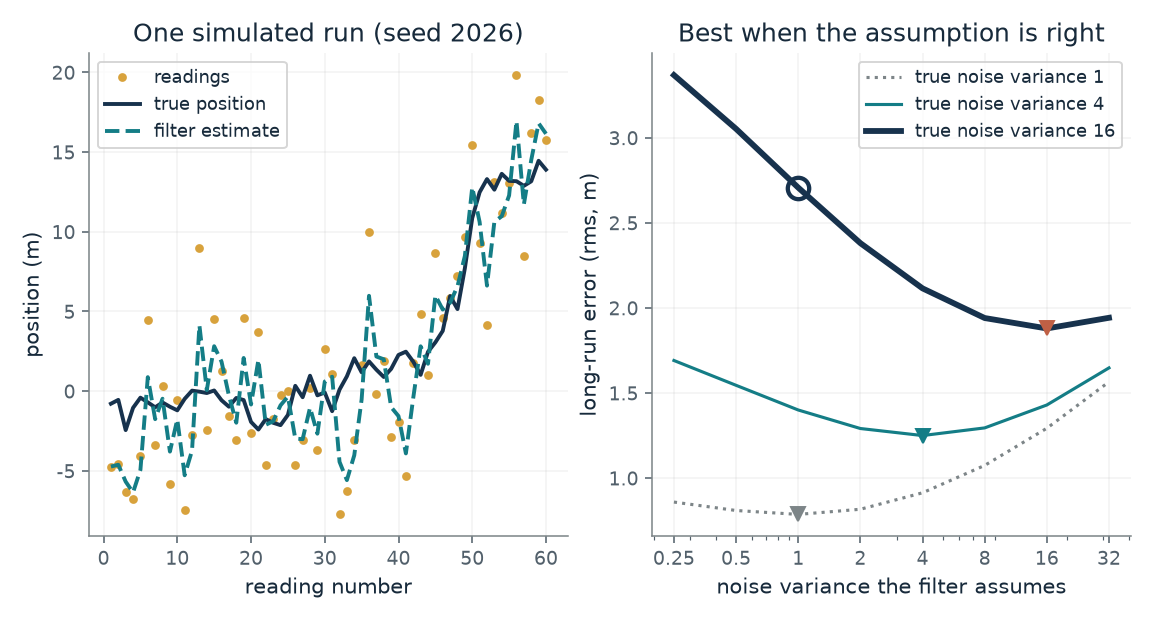

- **Filter error, long run (rms, m):** 2.71
- **Best possible with correct noise (m):** 1.88
- **Raw readings error (m):** 4
- **Gain the filter settles on:** 0.618

A filter assuming noise variance 1 when the true value is 16 has long-run error 2.71 m, against 1.88 m with the right assumption and 4 m for the raw readings. The curve on the right is exact; the run on the left is one seeded simulation.

Position wanders with variance Q = 1 per step. Assumed R = 1 gives a steady gain K = 0.618. With true R = 16, error variance = ((1 - K)^2 Q + K^2 R)/(1 - (1 - K)^2) = 7.33, so rms = 2.71 m. The best gain 0.221 gives 1.88 m.

In [6]:
figure, values, explanation = filter_noise_picture(**{'assumed_r': 1.0, 'true_r': 16.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a filter lose when it is told the wrong noise level?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Noise variance the filter assumes = 0.25, True noise variance of the sensor = 16.0: The overconfident filter still averages a little, so its error, about 3.4 m, is below the raw readings' 4 m, but it is about 1.8 times the 1.9 m that a filter with the right assumption achieves.

**Takeaway:** A filter does best when its noise assumption is right, and any wrong assumption costs accuracy in either direction.

**Why it matters:** A running estimator is only as good as the noise levels it is given. Adaptive methods try to revise them from the pattern of prediction errors, and the designers still choose how.

**In machines:** A basic filter takes its noise levels from the designer; an adaptive one revises them from data. Neither guarantees a good estimate when the model does not fit.

**Where it applies:** A scalar random-walk position, known process variance, unbiased unrelated reading errors, and long-run behavior. The left panel is one seeded run (seed 2026); the right panel is the exact long-run formula, not an average of runs.

**Check your understanding:** A filter assumes reading variance 1 but the true variance is 4. Is its long-run error closer to the raw readings or to the best achievable?

<details><summary>Show the answer</summary>

With Q = 1 the assumed noise gives a gain of 0.62 where the best is 0.39. The long-run error is about 1.40 m against 1.25 m at best and 2 m for the raw readings, so it is much closer to the best, though still worse.

</details>

*Source: Chapter 2, Same arithmetic, different machines. Simulation and exact steady-state algebra for a position that follows a random walk with variance 1 per step. The constants are made up. The chapter says a basic filter needs its noise levels supplied or tuned and can go wrong when they no longer fit; this illustration is the companion's own calculation, not a result from the chapter's sources.*

## C02-D06: How does a mind decide that two reports share one source?

A light flashes and a sound arrives. How much should the light pull the judged position of the sound?

Every rule so far assumed the two reports describe one thing. Here the observer asks how likely it is that one cause made both, given how far apart they are. The final answer mixes the blended estimate and the separate estimate in proportion to those chances. A larger gap makes one cause less likely, so the light pulls the sound less, as a fraction of the gap.

$$
P(C{=}1\mid x_V,x_A)=\frac{p_c\,L_1}{p_c\,L_1+(1-p_c)\,L_2}
$$

$$
\hat s_A=P(C{=}1\mid x_V,x_A)\,\hat s_{A,1}+\bigl(1-P(C{=}1\mid x_V,x_A)\bigr)\,\hat s_{A,2}
$$

**Symbols:** C: 1 if one cause made both signals, 2 if two causes did; x_V, x_A: measured light and sound positions (degrees); here equal to the true positions; p_c: expected chance of a common cause before looking; L_1, L_2: how well the data fit one cause and two causes; s-hat_{A,1}, s-hat_{A,2}: judged sound position if blended, and if kept separate

**Predict before looking:** As the light moves farther from the sound, predict what happens to the light's pull on the judged sound position, measured as a fraction of the way from the sound to the light.

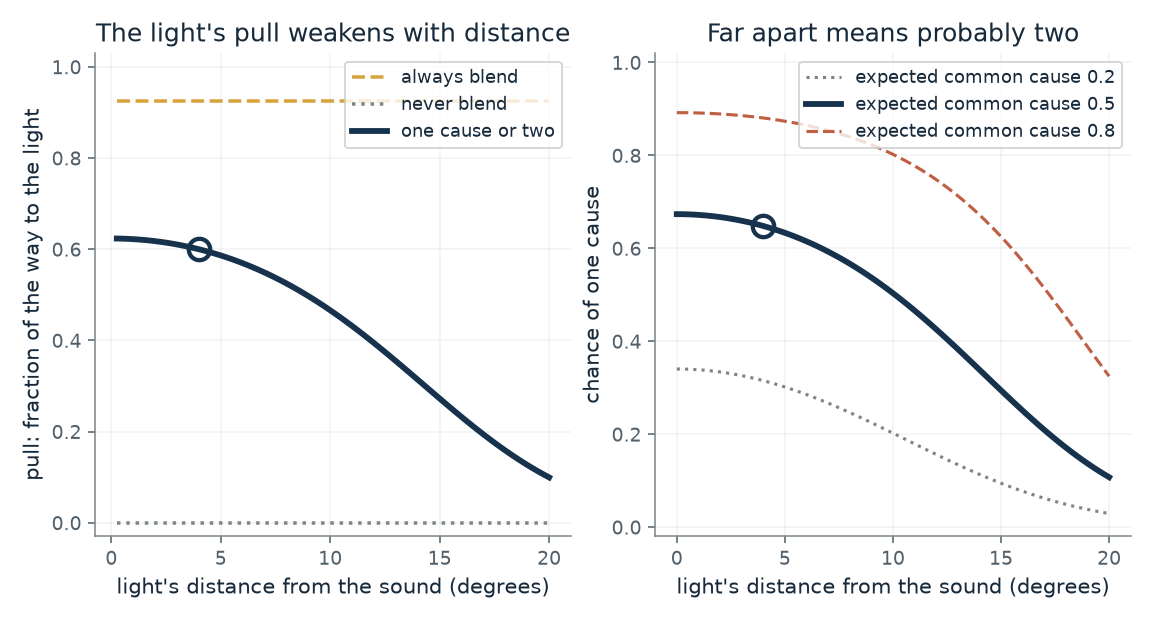

- **Chance the observer assigns to one cause:** 0.648
- **Pull of the light on the sound:** 0.6
- **Judged sound position if blended (degrees):** 3.7
- **Judged sound position, one cause or two (degrees):** 2.4

At 4 degrees apart, the observer gives one cause a chance of 0.648, so the judged sound position is 2.4 degrees, between the separate answer, 0, and the blended answer, 3.7. A higher expected chance of a common cause strengthens the pull.

Judged = P(one cause) x blended + (1 - P) x separate = 0.648 x 3.7 + 0.352 x 0 = 2.4 degrees. The sound is at 0 and the light measured at 4; error sds are 2 (sight), 8 (sound), prior 15.

In [7]:
figure, values, explanation = causal_inference_picture(**{'separation': 4, 'prior_common': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a mind decide that two reports share one source?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Light's distance from the sound (degrees) = 20, Expected chance of a common cause = 0.5: At 20 degrees apart the observer gives one cause a chance of only about 0.1, so the pull falls to about a tenth of the way to the light. Compare the 4 degree default, where the pull is about 0.6.

**Takeaway:** A mind that weighs one cause against two lets a nearby light pull the sound toward it and a distant light barely move it.

**Why it matters:** Blending is a mistake if the reports describe different things. A combiner has to infer which signals share a cause before it pools them.

**In brains and behavior:** The model accounted for 97 percent of the variation in nineteen people's pooled judgments, against 56 percent for a model that always blends. That is a fit to behavior with four adjustable settings; the study recorded nothing from the brain.

**In machines:** A fusion system can include a switch that compares one-cause and two-cause explanations and mixes the answers by their chances.

**Where it applies:** Gaussian errors, a Gaussian prior over position centered on 0, and a sound at 0. A noise-free trial shows the shape of the effect, not what a person with noisy measurements would report on average. A fit to behavior does not show how the judgments are produced.

**Check your understanding:** If you expect a common cause to be likely (0.8) and the light is 10 degrees from the sound, is the pull of the light larger or smaller than with an expectation of 0.2?

<details><summary>Show the answer</summary>

Larger. A higher expected chance of a common cause raises the chance assigned to one cause at every separation, so the judged sound position sits closer to the blended answer.

</details>

*Source: Chapter 2, One source or two. The one-cause-or-two model of Kording and colleagues (2007), described in words in the chapter; the formulas are written out here by the companion and are not printed in the chapter. The error sds (light 2, sound 8, prior 15 degrees) are made up, not the paper's fitted values, and the trials shown carry no measurement noise.*

## C02-D07: What changes when one sense is systematically off?

A pilot in cloud feels level while the instruments show a bank. How much weight should the body sense get?

Scatter averages away when reports are blended, but a steady offset does not. The squared error of the blend has one part from the offset, which grows with the square of the weight, and one part from scatter. A biased sense therefore deserves less weight than its scatter alone would give.

$$
\mathrm{MSE}(w)=w^2\left(b^2+\sigma_{\text{ear}}^2\right)+(1-w)^2\sigma_{\text{inst}}^2,\qquad w^{*}=\frac{\sigma_{\text{inst}}^2}{\sigma_{\text{inst}}^2+\sigma_{\text{ear}}^2+b^2}
$$

**Symbols:** w: weight on the inner-ear sense; the instrument gets 1 - w; b: the inner ear's steady offset (bias), in the same units as the errors; sigma_ear, sigma_inst: error standard deviations of the inner ear (3) and instrument (1); MSE: mean squared error of the blend; w*: the weight that minimizes the squared error

**Predict before looking:** With the inner ear's error sd at 3 and the instrument's at 1, the unbiased rule gives the ear a weight of 0.1. If the ear has a steady offset of 6, will the best weight go up, go down, or stay at 0.1?

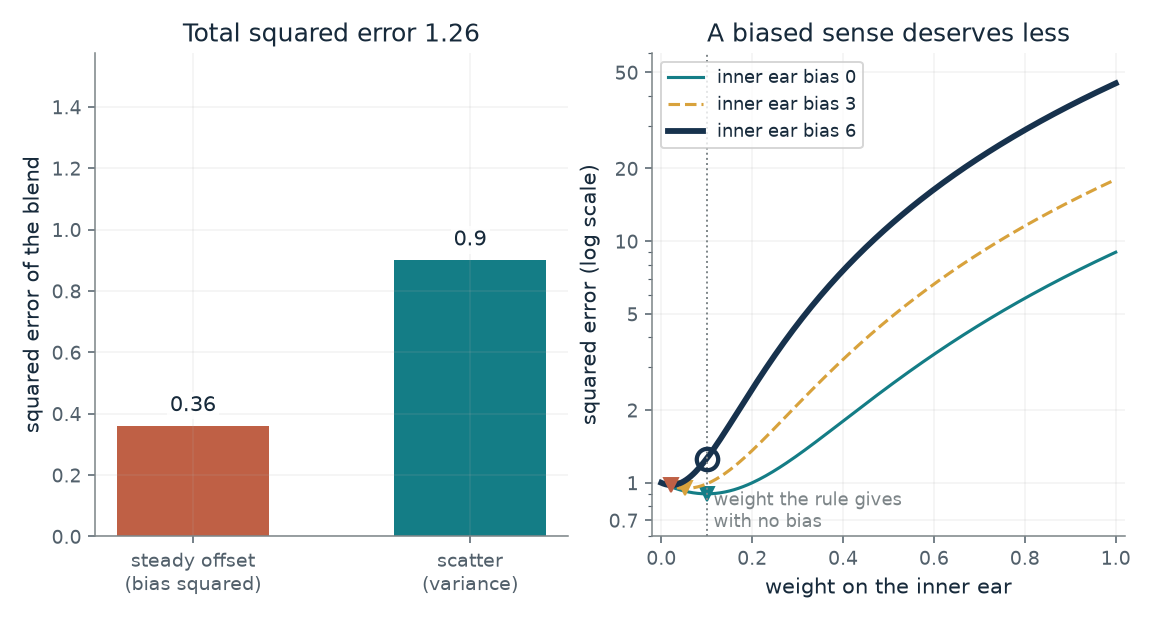

- **Squared error of the blend:** 1.26
- **Part from steady offset:** 0.36
- **Best weight on the inner ear:** 0.0217
- **Weight the unbiased rule gives:** 0.1

With inner-ear bias 6 and weight 0.1 on it, the blend's squared error is 1.26: 0.36 from the offset and 0.9 from scatter. The best weight is 0.0217, against 0.1 from the rule that assumes no bias.

MSE = w^2 (b^2 + sd_ear^2) + (1 - w)^2 sd_instrument^2 = 0.1^2 x (6^2 + 3^2) + (1 - 0.1)^2 x 1^2 = 1.26. Best w = sd_instrument^2 / (sd_instrument^2 + sd_ear^2 + b^2) = 1/(1 + 9 + 36) = 0.0217.

In [8]:
figure, values, explanation = bias_picture(**{'weight_on_body': 0.1, 'body_bias': 6})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What changes when one sense is systematically off?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the inner ear = 0.0, Inner ear steady offset (bias) = 6: With a bias of 6, the best weight on the inner ear falls to about 0.02, and among the listed weights 0 gives the smallest squared error, 1.0, against 1.26 at the 0.1 the unbiased rule suggests.

**Takeaway:** A steady offset is not averaged away, so a biased sense deserves less weight than its scatter alone would give it.

**Why it matters:** A precision-weighted blend assumes unbiased reports. When one source is known to mislead, adding its report with the usual weight can make the blend worse than the instrument alone.

**In brains and behavior:** In a sustained turn the inner ear can stop signaling the turn, so the pilot feels level. The handbook's advice is to trust the instruments over bodily sensation.

**In machines:** A filter can go wrong when its inputs share an unaccounted-for error or are biased; adding inputs does not remove the conditions for a useful blend.

**Where it applies:** Only the inner-ear report is biased; the instrument is unbiased; the two random errors are unrelated; the offset is known to the calculator. The study of pilots is not simulated; the chapter notes the handbook reports no outcome comparison.

**Check your understanding:** If the inner ear has no bias, what weight minimizes the squared error, and what is the squared error there?

<details><summary>Show the answer</summary>

With b = 0 the best weight is 1/(1 + 9) = 0.1, matching the precision rule, and the squared error is 0.01 x 9 + 0.81 x 1 = 0.9.

</details>

*Source: Chapter 2, A pilot must ignore the inner ear. Companion calculation built on the chapter's pilot example. The chapter gives no numbers; the error sds 3 and 1 and the biases 0, 3 and 6 are made up. The instruction to disregard the sensation is the FAA handbook's; treating it as zero weight is the chapter's interpretation, not a measured weight.*

## Bring it to your own question

Ask for the readings, how steady each source has been over repeated attempts, and whether the sources could share an error or a steady offset. Then choose the matching card: precision weights for two unrelated unbiased reports, the Kalman gain when a running prediction meets a new reading, the variance formula when errors may move together, the causal-inference card when the reports may not describe one thing. Report the blend, its claimed and actual spread, and the assumption that would break it.

Use the `mmi-ch02-building-perception` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.